# PZ data challenge: results across all task sets

This notebook puts the results of the four task-set notebooks (`pz_challenge_taskset{1..4}_e2e.ipynb`) side by side. It covers all 16 configurations: 4 task sets × 2 sims × 2 depths. It reads the trained models (the subtask 2 `.pkl` model files) those notebooks wrote to `OUT_DIR` (`outputs/znn` from scratch, `outputs/znn_pretrained_popcosmos` with pre-training, set by `PRETRAINING`; plus the method version `RUN` as a suffix) and trains nothing. All p(z)s are predicted here from those models with the current `znn` code, so the p(z) representation is the one `znn` produces now (a Student-t in log(1 + z) around F's prediction, with G's scale), whatever the run wrote as its own estimate files.

- **Part A, held-out scores** (the subtask 2 model files): each `.pkl` is reloaded and run on the same held-out split the task-set notebook used (`train_test_split` with `VAL_FRAC` and `SEED`). The results are scored with the challenge metrics, and the n(z) realizations of the copula are calibrated against the held-out redshift distribution. Predictions are on the photometry as given, as for the submission.
- **Part B, test-set p(z)** (optional, only with `PREDICT_TEST = True`): each model is run on its test file and the p(z) is written next to it as the subtask 1 file. The test redshifts are hidden, so this part only shows the predictions, i.e. the implied n(z) and the p(z) widths, set against the training redshift distribution. With `SUBMISSION = True` it also validates the 16 subtask 1 files and packs them with the models into the submission tarball.
- **Part C, challenge points** (optional, only with `SUBMISSION = True`, when preparing a submission): Part A's held-out metrics graded against the challenge tiers.

The held-out predictions are cached in `CACHE_DIR`, outside `OUT_DIR`. Delete the cache (or, for the test set, the estimate files in `OUT_DIR`) to recompute, e.g. after changing how `znn` builds the p(z). Figures (`.pdf`) and LaTeX tables (`.tex`) are saved to `PLOT_DIR`.

Run this from the repo root with the `qp` conda env as the kernel.

Plot conventions: **colour = task set** (blue TS1, green TS2, orange TS3, purple TS4), the same for all its setups. Where depths are overlaid, **line style = depth** (solid Y10, dashed Y1).

## Configuration

In [1]:
import znn  # run from the repo root so this picks up the local source

TASKSETS = [1, 2, 3, 4]
SIMS = ["cardinal", "flagship"]
SCENARIOS = ["1yr", "10yr"]
TASKSET_NAMES = {
    1: "1: representative",
    2: "2: spec-selected",
    3: "3: spec + COSMOS",
    4: "4: spec + COSMOS, blended",
}

DATA_DIR = "../pz_data_challenge/scripts/public"  # as in the task-set notebooks
# Which run to read; must match the task-set notebooks: "popcosmos" (the pre-training shipped with znn) or None (from scratch). Each choice
# writes to its own directory, so runs with and without pre-training never overwrite each other.
PRETRAINING = "popcosmos"
# Method version, appended to OUT_DIR so runs of different versions never overwrite each other ("" for none):
# the RUN of the task-set notebooks ("build_model_res_se_log1pz_moment_t", plus their NU); the p(z)s are predicted here
RUN = "build_model_res_se_log1pz_moment_t5"  # set by run_challenge.py
# where the runs are saved (models, submission files, cached predictions); run_challenge.py sets it to its
# --output-root
OUTPUT_ROOT = "outputs"
OUT_DIR = (f"{OUTPUT_ROOT}/znn" if PRETRAINING is None else f"{OUTPUT_ROOT}/znn_pretrained_{PRETRAINING}") + (f"_{RUN}" if RUN else "")  # the submission files written by the task-set notebooks
CACHE_DIR = f"{OUT_DIR}_predictions"  # held-out predictions (part A)
# Part B, at the end: predict every model's test set, written next to the model in OUT_DIR as the subtask 1 file,
# and show the implied n(z). It takes about as long as the held-out predictions, so it only runs when True
PREDICT_TEST = True
# Only needed when preparing a submission: validate Part B's subtask 1 files and pack them with the models into
# <SUBMISSION_NAME>.tgz in the repo root (with PREDICT_TEST), and grade the held-out metrics against the challenge
# tiers (Part C)
SUBMISSION = True
SUBMISSION_NAME = "znn_moments"
PLOT_DIR = "plots"  # figures and LaTeX tables are saved here, prefixed with the run name so runs never overwrite each other

# the held-out split: must match the task-set notebooks
VAL_FRAC = 0.2
SEED = 42
NZ_SEED = 42  # of the redshifts drawn from the p(z)s for the n(z) check

I0000 00:00:1795168729.184224   22174 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795168729.187030   22174 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795168729.505995   22174 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795168731.197094   22174 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

In [2]:
import itertools
import os
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import qp
from qp.metrics.pit import PIT
from sklearn.model_selection import train_test_split

from pz_data_challenge import scoring

os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(PLOT_DIR, exist_ok=True)

CONFIGS = list(itertools.product(TASKSETS, SIMS, SCENARIOS))
# one colour per task set, the same for all its setups; its colour map is used for 2D densities
TASKSET_CMAPS = {1: "Blues", 2: "Greens", 3: "Oranges", 4: "Purples"}
COLORS = {t: plt.get_cmap(cmap)(0.7) for t, cmap in TASKSET_CMAPS.items()}
LINESTYLES = {"1yr": "--", "10yr": "-"}
TRAIN_COLOR = "0.6"
# how sims and depths are written in plots and tables
SIM_LABELS = {"cardinal": "Cardinal", "flagship": "Flagship"}
DEPTH_LABELS = {"1yr": "Y1", "10yr": "Y10"}


def label(sim, scenario):
    return f"{SIM_LABELS[sim]} {DEPTH_LABELS[scenario]}"


def style(taskset, sim, scenario):
    return dict(color=COLORS[taskset], ls=LINESTYLES[scenario], lw=1.5, label=label(sim, scenario))


def save(fig, name):
    fig.savefig(os.path.join(PLOT_DIR, f"{os.path.basename(OUT_DIR)}_{name}.pdf"), bbox_inches="tight")


def save_latex(df, name, columns, caption):
    # Write df as a booktabs LaTeX table (columns: {df column: LaTeX header}) to PLOT_DIR and print it. Values of
    # 10 or more (the Anderson-Darling statistic) get one decimal, the rest four.
    df = df[list(columns)].rename(columns=columns, index=SIM_LABELS | DEPTH_LABELS)
    tex = df.rename_axis(["Task set", "Sim", "Depth"]).to_latex(
        float_format=lambda v: f"{v:.1f}" if abs(v) >= 10 else f"{v:.4f}", multirow=True, caption=caption,
        label=f"tab:{name}", position="htbp",
    )
    # a rule between task sets only, not between sims
    tex = re.sub(r"\\cline\{1-\d+\} \\cline\{2-\d+\}\n", r"\\midrule\n", tex)
    tex = re.sub(r"\\cline\{2-\d+\}\n", "", tex).replace("\\midrule\n\\bottomrule", "\\bottomrule")
    with open(os.path.join(PLOT_DIR, f"{os.path.basename(OUT_DIR)}_{name}.tex"), "w") as f:
        f.write(tex)
    print(tex)


def path(kind, taskset, sim, scenario):
    if kind in ("training", "test"):
        return os.path.join(DATA_DIR, f"pz_challenge_taskset_{taskset}_{sim}_{kind}_{scenario}.hdf5")
    ext = "hdf5" if kind == "pz_estimate" else "pkl"
    return os.path.join(OUT_DIR, f"pz_challenge_taskset_{taskset}_{sim}_{kind}_{scenario}.{ext}")


missing = [p for c in CONFIGS if not os.path.exists(p := path("pz_model", *c))]
assert not missing, f"missing model files: {missing}"

## Reference redshifts

These are the same labels as in the task-set notebooks. Task sets 1 and 2 use `redshift`. Task sets 3 and 4 use `redshift` for spectroscopically selected objects and `redshift_manyband` for COSMOS-only objects, so scores on task sets 3 and 4 include the label noise of the COSMOS-only objects.

In [3]:
SPEC_SURVEYS = ["DEEP2_LSST", "DESI_BGS", "DESI_ELG_LOP", "DESI_LRG", "VVDSf02", "zCOSMOS"]


def reference_redshifts(train):
    # Reference redshift per training object.
    z_spec = train["redshift"].to_numpy()
    if "COSMOS" not in train:  # task sets 1 and 2
        return z_spec
    is_spec = train[[c for c in SPEC_SURVEYS if c in train]].astype(bool).any(axis=1).to_numpy()
    is_cosmos_only = train["COSMOS"].astype(bool).to_numpy() & ~is_spec
    z_ref = np.where(is_cosmos_only, train["redshift_manyband"].to_numpy(), z_spec)
    assert np.isfinite(z_ref).all()
    return z_ref


# Part A: held-out scores

For each configuration the model file is reloaded and run on the held-out 20% of the training file. The model was trained on the other 80%, the same split as in the task-set notebooks. Each held-out set is scored on all of its objects.

Only task set 1 has a held-out set that is representative of its test set. For the other task sets these scores are **optimistic** for the test set.


In [4]:
def heldout_predictions(taskset, sim, scenario):
    # Held-out reference z, i-mag, zmode, the p(z) mean and std, and the model's p(z) (a qp
    # ensemble) under "pz". Cached in CACHE_DIR: the arrays in <stem>.npz, the p(z) in <stem>.hdf5.
    stem = os.path.join(CACHE_DIR, f"taskset_{taskset}_{sim}_{scenario}_pz")
    if os.path.exists(f"{stem}.npz") and os.path.exists(f"{stem}.hdf5"):
        return dict(np.load(f"{stem}.npz")) | {"pz": qp.read(f"{stem}.hdf5")}

    train = znn.read_catalog(path("training", taskset, sim, scenario))
    z_ref = reference_redshifts(train)
    _, idx_val = train_test_split(np.arange(len(train)), test_size=VAL_FRAC, random_state=SEED)
    val = train.iloc[idx_val]

    model, features = znn.load_model_file(path("pz_model", taskset, sim, scenario))
    pz = znn.predict(model, val, **features)
    out = {
        "z_ref": z_ref[idx_val],
        "mag_i": val["mag_i_lsst"].to_numpy(),
        "zmode": np.squeeze(pz.ancil["zmode"]),
        **dict(zip(("mean", "std"), map(np.ravel, znn.predictions_mean_std(pz)))),
    }
    np.savez(f"{stem}.npz", **out)
    pz.write_to(f"{stem}.hdf5")
    return out | {"pz": pz}


heldout = {}
for c in CONFIGS:
    print("held-out predictions:", *c)
    heldout[c] = heldout_predictions(*c)

held-out predictions: 1 cardinal 1yr
held-out predictions: 1 cardinal 10yr
held-out predictions: 1 flagship 1yr
held-out predictions: 1 flagship 10yr
held-out predictions: 2 cardinal 1yr
held-out predictions: 2 cardinal 10yr
held-out predictions: 2 flagship 1yr
held-out predictions: 2 flagship 10yr
held-out predictions: 3 cardinal 1yr
held-out predictions: 3 cardinal 10yr
held-out predictions: 3 flagship 1yr
held-out predictions: 3 flagship 10yr
held-out predictions: 4 cardinal 1yr
held-out predictions: 4 cardinal 10yr
held-out predictions: 4 flagship 1yr
held-out predictions: 4 flagship 10yr


In [5]:
def challenge_metrics(z_ref, zmode, pz):
    # The challenge's seven scored metrics, computed as in the task-set notebooks.
    dz = (zmode - z_ref) / (1 + z_ref)
    bias, _, scatter, _, abs_outlier_rate = znn.get_biweight_mean_sigma_outlier(dz)
    pit = PIT(pz, z_ref)
    return {
        "mean": bias,
        "std": scatter,
        "abs_outlier_rate": abs_outlier_rate,
        "ks": pit.evaluate_PIT_KS().statistic,
        "CvM": pit.evaluate_PIT_CvM().statistic,
        "ksamp": pit.evaluate_PIT_anderson_ksamp().statistic,
        # qp derives this from a spline fit to the PIT quantiles and it breaks down (negative or huge values)
        # when PIT piles up at 0 or 1; the challenge evaluator uses the same call, so it is what gets scored
        "outlier": pit.evaluate_PIT_outlier_rate(),
    }, pit.pit_samps


results, pits = {}, {}
for c, h in heldout.items():
    results[c], pits[c] = challenge_metrics(h["z_ref"], h["zmode"], h["pz"])

# ks and CvM are only used for the challenge points (Part C)
table = pd.DataFrame(results).T[["mean", "std", "abs_outlier_rate", "ksamp", "outlier"]]
table.index.names = ["taskset", "sim", "scenario"]
table.round(4)

/home/jaimerz/Documents/UCL/mlpz_cnn_deepset/.venv/lib/python3.12/site-packages/qp/metrics/array_metrics.py:27: UserWarning: Parameter `variant` has been introduced to replace `midrank`; `midrank` will be removed in SciPy 1.19.0. Specify `variant` to silence this warning. Note that the returned object will no longer be unpackable as a tuple, and `critical_values` will be omitted.
  return stats.anderson_ksamp([p_random_variables, q_random_variables], **kwargs)
/home/jaimerz/Documents/UCL/mlpz_cnn_deepset/.venv/lib/python3.12/site-packages/qp/metrics/array_metrics.py:27: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  return stats.anderson_ksamp([p_random_variables, q_random_variables], **kwargs)


mean     std  abs_outlier_rate     ksamp  outlier
taskset sim      scenario                                                     
1       cardinal 1yr      -0.0003  0.0168            0.0012    5.2741   0.0000
                 10yr     -0.0000  0.0106            0.0000    7.1826   0.0000
        flagship 1yr      -0.0005  0.0181            0.0008    4.6228   0.0000
                 10yr     -0.0000  0.0108            0.0000    8.1022   0.0000
2       cardinal 1yr       0.0010  0.0217            0.0064   30.6658   0.0000
                 10yr      0.0004  0.0135            0.0003   20.2808   0.0000
        flagship 1yr      -0.0001  0.0245            0.0052    3.2516   0.0000
                 10yr     -0.0012  0.0133            0.0001   39.7641   0.0000
3       cardinal 1yr       0.0042  0.0289            0.0466  196.2512   0.0065
                 10yr     -0.0000  0.0222            0.0245   29.6320   0.0083
        flagship 1yr      -0.0022  0.0403            0.0708    5.7859   0.0081
                 10yr     -0.0059  0.0246            0.0351  171.4932   0.0096
4       cardinal 1yr       0.0029  0.0270            0.0476  134.2099   0.0073
                 10yr     -0.0023  0.0180            0.0265   51.3852   0.0082
        flagship 1yr      -0.0034  0.0381            0.0752   25.0292   0.0076
                 10yr     -0.0029  0.0286            0.0427   24.2210   0.0094

### p(z) metrics

What each column of the table above measures, all on the held-out set. Lower is better for all of them except `mean`, which should be close to 0.

Point-estimate metrics, on Δz = (zmode − z_ref)/(1 + z_ref). They are computed after 3σ-clipping Δz until convergence, as in `znn.get_biweight_mean_sigma_outlier`:
- `mean`: the bias, the biweight location of the clipped Δz.
- `std`: the scatter, the biweight scale of the clipped Δz (a robust standard deviation).
- `abs_outlier_rate`: the fraction of *all* objects (not clipped) with |Δz| > 0.2.

Calibration metrics, on the PIT (the CDF of each p(z) evaluated at its z_ref). These should be uniform on [0, 1] if the p(z)s are calibrated:
- `ksamp`: Anderson–Darling k-sample statistic between the PIT values and a uniform sample. It weights the tails (PIT near 0 and 1) more than a KS test does, so it reacts most to catastrophic misses. It grows with the number of objects.
- `outlier`: the fraction of PIT values below 0.0001 or above 0.9999, i.e. z_ref far out in the tails of its p(z). qp estimates it from a spline fit to the PIT quantiles, which breaks down (negative or huge values) when PIT piles up at 0 or 1. The challenge evaluator uses the same call, so this is the value that gets scored.

The challenge also scores the KS and Cramér–von Mises statistics of the PIT. They are computed for Part C but left out of the table; the PIT histograms below show the calibration directly.


In [6]:
save_latex(
    table,
    "pz_metrics",
    {
        "mean": r"bias",
        "std": r"$\sigma$",
        "abs_outlier_rate": r"$f_{|\Delta z| > 0.2}$",
        "ksamp": r"AD",
        "outlier": r"$f_\mathrm{PIT\,out}$",
    },
    r"p(z) metrics on the held-out set. Point estimates: bias, scatter $\sigma$ and outlier fraction of "
    r"$\Delta z = (z_\mathrm{mode} - z_\mathrm{ref})/(1 + z_\mathrm{ref})$. Calibration: Anderson--Darling "
    r"statistic of the PIT against uniform and the fraction of PIT outliers.",
)


\begin{table}[htbp]
\caption{p(z) metrics on the held-out set. Point estimates: bias, scatter $\sigma$ and outlier fraction of $\Delta z = (z_\mathrm{mode} - z_\mathrm{ref})/(1 + z_\mathrm{ref})$. Calibration: Anderson--Darling statistic of the PIT against uniform and the fraction of PIT outliers.}
\label{tab:pz_metrics}
\begin{tabular}{lllrrrrr}
\toprule
 &  &  & bias & $\sigma$ & $f_{|\Delta z| > 0.2}$ & AD & $f_\mathrm{PIT\,out}$ \\
Task set & Sim & Depth &  &  &  &  &  \\
\midrule
\multirow[t]{4}{*}{1} & \multirow[t]{2}{*}{Cardinal} & Y1 & -0.0003 & 0.0168 & 0.0012 & 5.2741 & 0.0000 \\
 &  & Y10 & -0.0000 & 0.0106 & 0.0001 & 7.1826 & 0.0000 \\
 & \multirow[t]{2}{*}{Flagship} & Y1 & -0.0005 & 0.0181 & 0.0008 & 4.6228 & 0.0000 \\
 &  & Y10 & -0.0000 & 0.0108 & 0.0000 & 8.1022 & 0.0000 \\
\midrule
\multirow[t]{4}{*}{2} & \multirow[t]{2}{*}{Cardinal} & Y1 & 0.0010 & 0.0217 & 0.0063 & 30.7 & 0.0000 \\
 &  & Y10 & 0.0004 & 0.0135 & 0.0003 & 20.3 & 0.0000 \\
 & \multirow[t]{2}{*}{Flagship

### PIT

PIT histograms on the held-out set. A flat histogram means the p(z) is calibrated. A U shape means it is too narrow, and a hump means it is too wide.

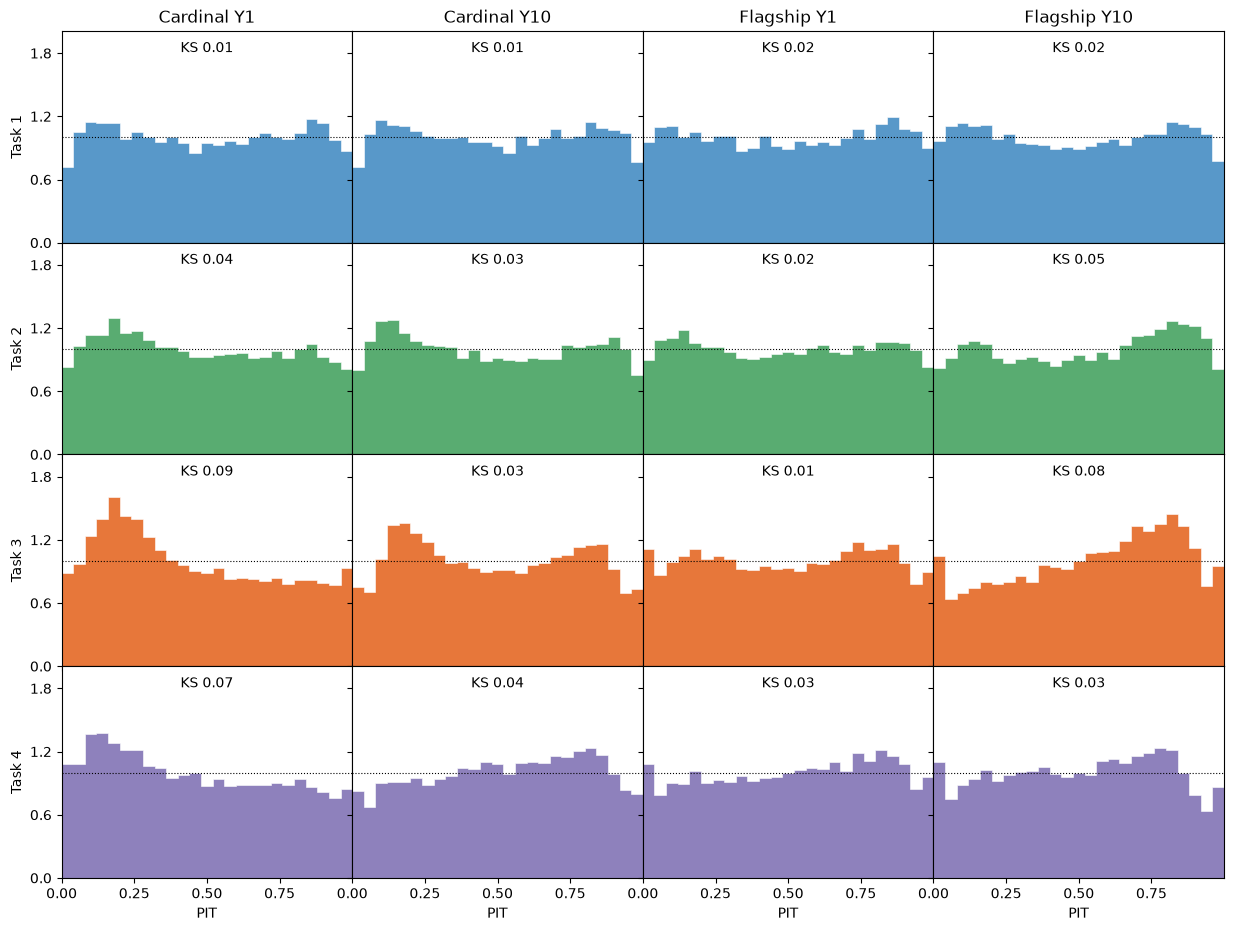

In [7]:
from matplotlib.ticker import MaxNLocator

pit_bins = np.linspace(0, 1, 26)
top = 0
fig, axes = plt.subplots(4, 4, figsize=(15, 11), sharex=True, sharey=True, gridspec_kw=dict(hspace=0, wspace=0))
for row, taskset in enumerate(TASKSETS):
    for col, (sim, scenario) in enumerate(itertools.product(SIMS, SCENARIOS)):
        ax = axes[row, col]
        heights, _, _ = ax.hist(pits[(taskset, sim, scenario)], pit_bins, density=True, color=COLORS[taskset],
                histtype="stepfilled", alpha=0.8, ec="white", lw=0.5)
        ax.axhline(1, color="k", lw=0.8, ls=":")
        ks = results[(taskset, sim, scenario)]["ks"]
        ax.text(0.5, 0.95, f"KS {ks:.2f}", transform=ax.transAxes, ha="center", va="top", fontsize=10,
                bbox=dict(fc="white", ec="none", alpha=0.8, pad=1))
        top = max(top, heights.max())
        if row == 0:
            ax.set_title(label(sim, scenario), fontsize=12)
        if col == 0:
            ax.set_ylabel(f"Task {taskset}")
        if row == 3:
            ax.set_xlabel("PIT")
# with no gaps, keep the ticks off the panel edges so labels of neighbouring panels do not touch
axes[0, 0].set_xlim(0, 1)
axes[0, 0].set_ylim(0, 1.25 * top)  # headroom for the KS labels
axes[0, 0].set_xticks([0, 0.25, 0.5, 0.75])
axes[0, 0].yaxis.set_major_locator(MaxNLocator(nbins=4, prune="upper"))
save(fig, "pit")
plt.show()

### Point estimates

`zmode` against the reference redshift on the held-out set (log-density 2D histogram). The dashed lines mark |Δz|/(1+z) = 0.2, the outlier threshold.

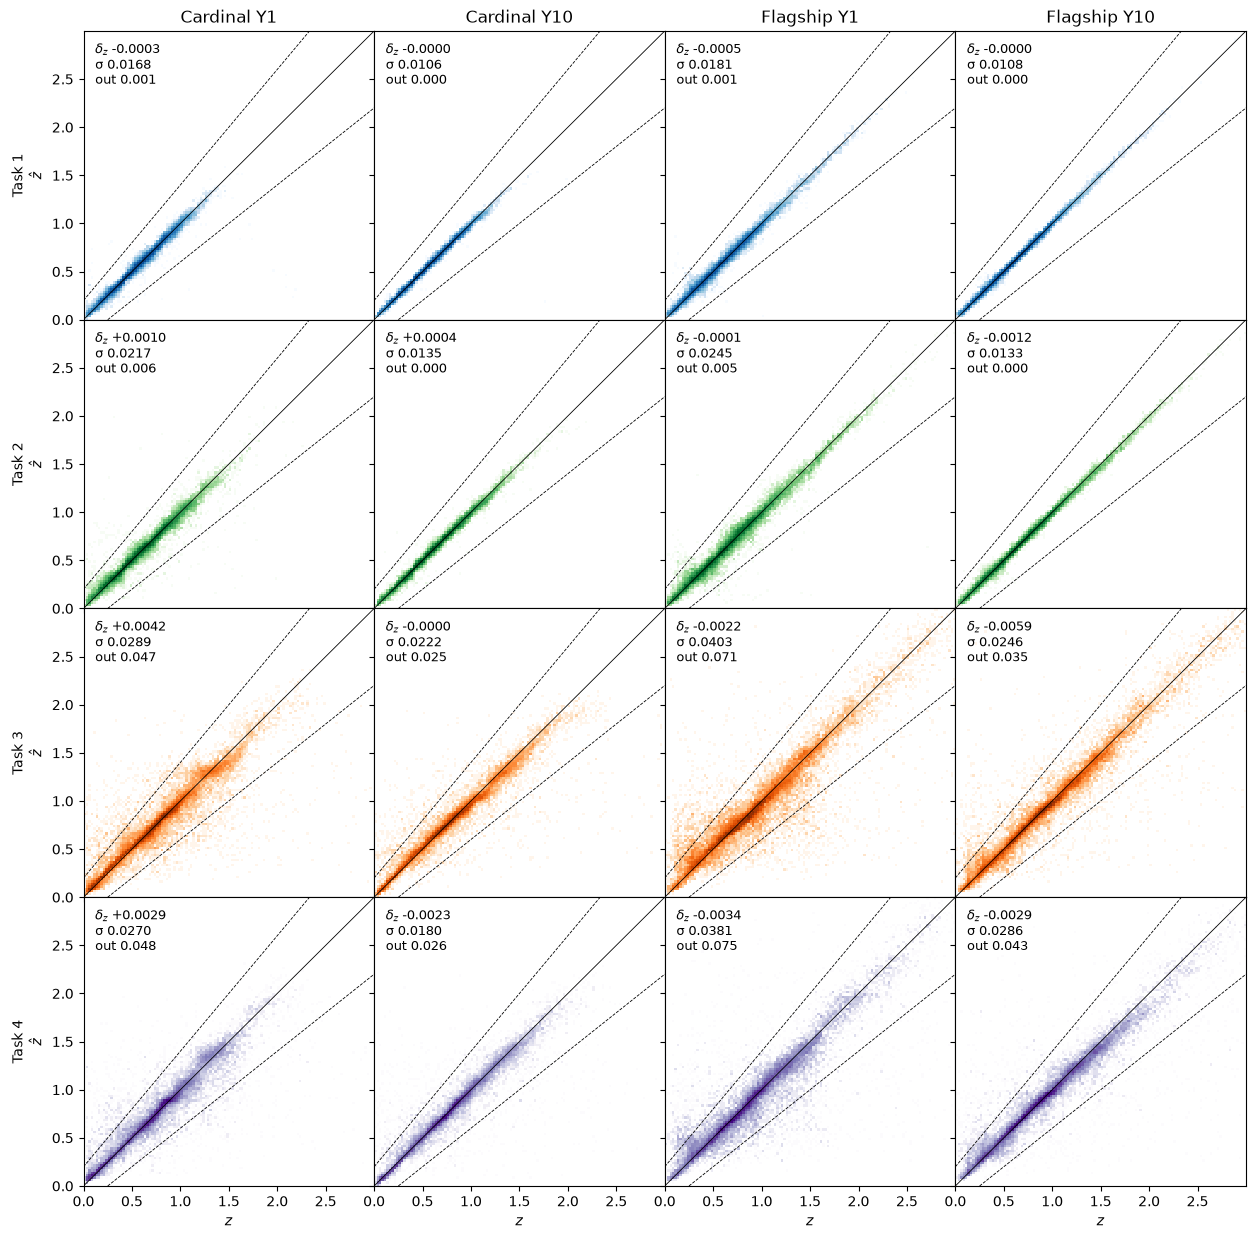

In [8]:
from matplotlib.colors import LogNorm

zb = np.linspace(0, 3, 121)
fig, axes = plt.subplots(4, 4, figsize=(15, 15), sharex=True, sharey=True, gridspec_kw=dict(hspace=0, wspace=0))
for row, taskset in enumerate(TASKSETS):
    for col, (sim, scenario) in enumerate(itertools.product(SIMS, SCENARIOS)):
        ax = axes[row, col]
        h = heldout[(taskset, sim, scenario)]
        ax.hist2d(h["z_ref"], h["zmode"], bins=[zb, zb], cmap=TASKSET_CMAPS[taskset], norm=LogNorm(), rasterized=True)
        ax.plot(zb, zb, color="k", lw=0.6)
        for sgn in (-1, 1):
            ax.plot(zb, zb + sgn * 0.2 * (1 + zb), color="k", lw=0.6, ls="--")
        v = table.loc[(taskset, sim, scenario)]
        ax.text(0.04, 0.96, f"$\\delta_z$ {v['mean']:+.4f}\nσ {v['std']:.4f}\nout {v['abs_outlier_rate']:.3f}",
                transform=ax.transAxes, va="top", fontsize=9)
        if row == 0:
            ax.set_title(label(sim, scenario), fontsize=12)
        if col == 0:
            ax.set_ylabel(f"Task {taskset}\n$\\hat{{z}}$")
        if row == 3:
            ax.set_xlabel("$z$")
axes[0, 0].set_xlim(0, 3)
axes[0, 0].set_ylim(0, 3)
# ticks stop short of 3 so labels of neighbouring panels do not touch
axes[0, 0].set_xticks(np.arange(0, 3, 0.5))
axes[0, 0].set_yticks(np.arange(0, 3, 0.5))
save(fig, "zphot_vs_zref")
plt.show()

## n(z) calibration

### Coherent n(z) realizations: a Gaussian copula in the latent space

Drawing each galaxy's redshift independently from its own p(z) gives n(z) realizations whose spread falls as 1/√M, far narrower than the actual error of the stacked n(z): galaxies that F sees as similar share part of their error. The copula keeps **every galaxy's p(z) exactly as it is** and only correlates the draws (the equations are those of the paper's copula section, `copula_section.tex`):

- z_j = CDF_j⁻¹(Φ(g_j)), with g ~ N(0, K) and K_jj = 1, so each z_j follows its own p(z) whatever K is;
- similarity: the activations ξ_j entering F's last layer (units active on the training set) are projected on the principal components of their training-set covariance, each scaled to unit variance, w_j = Λ^(-1/2) Vᵀ (ξ_j − ⟨ξ⟩), and cos θ_jj' = w_j · w_j' / (|w_j| |w_j'|);
- K_jj' = ρ cos θ_jj', sampled without forming K as g_j = √ρ w_j · a / |w_j| + √(1 − ρ) ε_j, with a ~ N(0, I) common to all galaxies and ε_j ~ N(0, 1) independent.

**How the data set ρ.** ρ is fitted on the training set, the same labelled galaxies F and H were trained on. Each galaxy's PIT score, u_j = Φ⁻¹(CDF_j(z_ref,j)), is under the copula its g_j. The galaxies are grouped by the mode of their p(z) into the 60 n(z) bins of width 0.05 on [0, 3]; the copula predicts that the mean PIT scores of the bins, u_q, are Gaussian with covariance Σ_qq' = ρ w̄_q · w̄_q' + δ_qq' (1 − ρ)/M_q, where w̄_q is the mean of the unit vectors w_j/|w_j| of bin q (its diagonal is Var(g_q) = 1/M_q + ρ S_q, with S_q = M_q⁻² Σ_{j≠j'} cos θ_jj'). ρ maximises that Gaussian likelihood of the measured u_q (bins with at least two galaxies; galaxies with |u| > 4 left out; the u_j divided by their standard deviation).

`znn.fit_copula` fits it and `znn.sample_redshifts` draws the correlated redshifts; the copula is a plain dict (ρ, the active units, ⟨ξ⟩ and the whitening matrix).

**Checking the n(z) on the held-out set.** There is no labelled n(z) for the test set, but the held-out galaxies have reference redshifts, so their true n(z) is known. `N_VAL_DRAWS` realizations of the held-out galaxies' redshifts are drawn, with the copula (ρ from the training set) and independently (ρ = 0), and each is histogrammed in the 60 `NZ_BINS`. The predicted n(z) is the mean of the realizations, and its errors their covariance **C** over the n(z) bins. The truth is then compared with the prediction through

χ² = h rᵀ C⁻¹ r,   r = n_true − ⟨n⟩,

with h = (N_real − ν − 2)/(N_real − 1) the Hartlap correction for inverting a covariance estimated from N_real realizations, over ν n(z) bins. If the realizations describe the error of the n(z), χ² follows a χ² distribution with ν degrees of freedom, so χ²/ν ≈ 1 ± √(2/ν). The full covariance also tests the correlations between bins, which the copula introduces: the truth must deviate from the prediction in the coherent patterns the copula draws, not only by the size of its error bars.

Only n(z) bins expected to hold at least `NZ_MIN_COUNT` held-out galaxies are used. In task sets 3 and 4 the reference redshifts of COSMOS-only galaxies are many-band photo-zs, so their label errors enter both the PITs the copula is fitted on and the "true" n(z).

In [9]:
NZ_BINS = np.linspace(0, 3, 61)  # n(z) bin edges: 60 bins of width 0.05, as the training histogram
COPULA_N_DRAWS = 200  # n(z) realizations of the test set (Part B)
N_VAL_DRAWS = 300  # n(z) realizations of the held-out set
NZ_MIN_COUNT = 20  # n(z) bins in the calibration: expected to hold at least this many held-out galaxies
COPULA_SEED = 0
TOMO_EDGES = {1: np.array([0.0, 0.32, 0.47, 0.61, 0.78, 2.5])} | {
    t: np.array([0.0, 0.42, 0.64, 0.87, 1.20, 2.5]) for t in (2, 3, 4)
}


def tomo_bins(zmode, taskset):
    # tomographic bin of each galaxy, by the mode of its p(z) (-1 outside the edges)
    t = np.digitize(zmode, TOMO_EDGES[taskset]) - 1
    t[t >= len(TOMO_EDGES[taskset]) - 1] = -1
    return t


def split_training_file(taskset, sim, scenario):
    # The training set (the galaxies the saved models were trained on) and the validation set (the VAL_FRAC split of
    # the training file, which they never saw; in the order of heldout[c], Part A), each with its reference redshifts
    train = znn.read_catalog(path("training", taskset, sim, scenario))
    z_ref = reference_redshifts(train)
    idx_fit, idx_val = train_test_split(np.arange(len(train)), test_size=VAL_FRAC, random_state=SEED)
    return (train.iloc[idx_fit], z_ref[idx_fit]), (train.iloc[idx_val], z_ref[idx_val])


copulas = {}


def model_and_copula(taskset, sim, scenario):
    # The saved model and its copula, fitted on the model's training set (once per configuration)
    c = (taskset, sim, scenario)
    model, features = znn.load_model_file(path("pz_model", *c))
    if c not in copulas:
        (train, z_train), _ = split_training_file(*c)
        copulas[c] = znn.fit_copula(model, train, **features, Y=z_train)
    return model, features, copulas[c]

z_mid = 0.5 * (NZ_BINS[1:] + NZ_BINS[:-1])
ROWS = [(sim, scenario) for sim in SIMS for scenario in SCENARIOS]  # rows of the n(z) figures; columns: task sets


In [10]:
def heldout_nz(taskset, sim, scenario):
    # N_VAL_DRAWS realizations of the held-out galaxies' redshifts, independent (rho = 0) and with the copula fitted
    # on the training set, each histogrammed in NZ_BINS (an n(z) realization); with the true n(z) of the held-out
    # galaxies. Cached in CACHE_DIR.
    c = (taskset, sim, scenario)
    cache = os.path.join(CACHE_DIR, f"taskset_{taskset}_{sim}_{scenario}_nz_copula_pca.npz")
    model_file = path("pz_model", *c)
    model, features, copula = model_and_copula(*c)
    # reuse the cached realizations only if they were drawn from this model and this copula
    if os.path.exists(cache) and os.path.getmtime(cache) >= os.path.getmtime(model_file):
        cached = dict(np.load(cache))
        if np.isclose(cached["rho"], copula["rho"], rtol=0, atol=1e-10):
            return cached
    _, (val, z_val) = split_training_file(*c)  # in the order of heldout[c]
    width = np.diff(NZ_BINS)
    out = {"rho": copula["rho"], "n_gal": len(z_val), "nz_true": np.histogram(z_val, NZ_BINS)[0] / len(z_val) / width}
    for name, rho in [("indep", 0.0), ("copula", None)]:
        zs = znn.sample_redshifts(model, copula, val, **features, n_draws=N_VAL_DRAWS,
                                  rng=np.random.default_rng(COPULA_SEED + 1), rho=rho)
        out[f"nz_{name}"] = np.array([np.histogram(z, NZ_BINS)[0] for z in zs]) / len(z_val) / width
    np.savez(cache, **out)
    return out


def chi2(truth, realizations):
    # chi^2 of the truth against the mean and covariance of the realizations (rows), with the Hartlap correction
    # for the inverse of the estimated covariance
    r = truth - realizations.mean(0)
    n, dof = realizations.shape
    return (n - dof - 2) / (n - 1) * r @ np.linalg.solve(np.atleast_2d(np.cov(realizations, rowvar=False)), r)


nz_val, nz_used = {}, {}
rows = {}
for c in CONFIGS:
    print("held-out n(z) realizations:", *c)
    g = nz_val[c] = heldout_nz(*c)
    nz_used[c] = g["nz_copula"].mean(0) * np.diff(NZ_BINS) * g["n_gal"] >= NZ_MIN_COUNT
    dof = int(nz_used[c].sum())
    rows[c] = {"ρ": g["rho"], "n(z) bins": dof}
    for name, lab in [("indep", "independent"), ("copula", "copula")]:
        rows[c][f"χ²/ν: {lab}"] = chi2(g["nz_true"][nz_used[c]], g[f"nz_{name}"][:, nz_used[c]]) / dof

copula_val = pd.DataFrame(rows).T
copula_val.index.names = ["taskset", "sim", "scenario"]
print("n(z) calibration on the held-out set: rho fitted on the training set; chi^2 per degree of freedom (n(z) bins) of")
print("the true n(z) against the mean and covariance of the realizations (about 1 if calibrated)")
display(copula_val.style.format({"ρ": "{:.3f}", "n(z) bins": "{:d}"}, precision=2))

held-out n(z) realizations: 1 cardinal 1yr


E0000 00:00:1795168747.095282   22174 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


held-out n(z) realizations: 1 cardinal 10yr
held-out n(z) realizations: 1 flagship 1yr
held-out n(z) realizations: 1 flagship 10yr
held-out n(z) realizations: 2 cardinal 1yr
held-out n(z) realizations: 2 cardinal 10yr
held-out n(z) realizations: 2 flagship 1yr
held-out n(z) realizations: 2 flagship 10yr
held-out n(z) realizations: 3 cardinal 1yr
held-out n(z) realizations: 3 cardinal 10yr
held-out n(z) realizations: 3 flagship 1yr
held-out n(z) realizations: 3 flagship 10yr
held-out n(z) realizations: 4 cardinal 1yr
held-out n(z) realizations: 4 cardinal 10yr
held-out n(z) realizations: 4 flagship 1yr
held-out n(z) realizations: 4 flagship 10yr
n(z) calibration on the held-out set: rho fitted on the training set; chi^2 per degree of freedom (n(z) bins) of
the true n(z) against the mean and covariance of the realizations (about 1 if calibrated)


ValueError: Unknown format code 'd' for object of type 'float'

### Held-out n(z)

The true n(z) of the held-out galaxies (black) against the mean of the copula realizations, with their spread as error bars (coloured), and the spread of independent sampling (thin black bars).

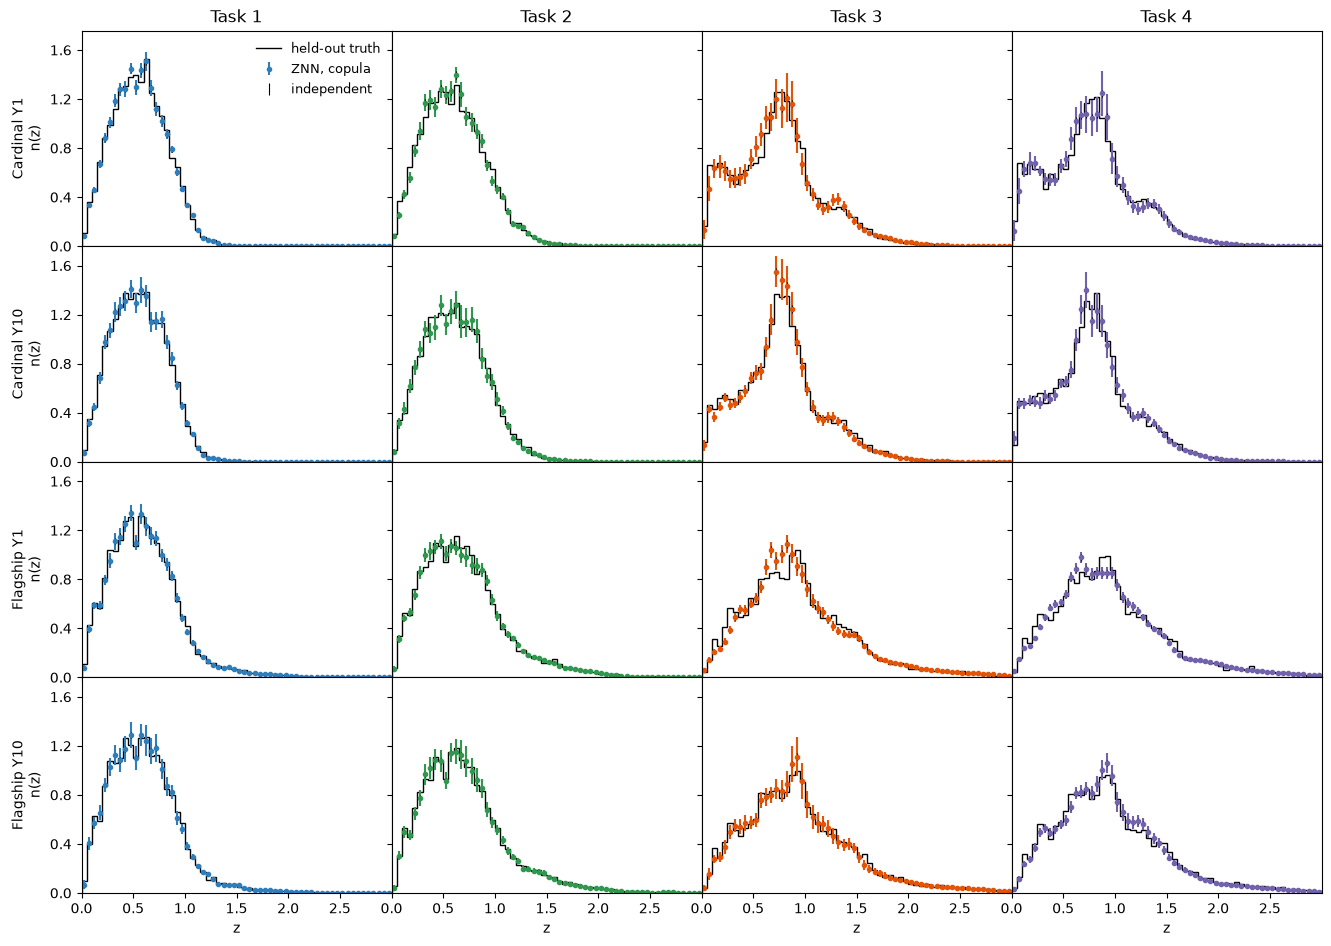

In [11]:
fig, axes = plt.subplots(len(ROWS), len(TASKSETS), figsize=(16, 2.8 * len(ROWS)), sharex=True, sharey=True,
                         gridspec_kw=dict(hspace=0, wspace=0))
for col, taskset in enumerate(TASKSETS):
    for row, (sim, scenario) in enumerate(ROWS):
        c = (taskset, sim, scenario)
        g, ax = nz_val[c], axes[row, col]
        ax.stairs(g["nz_true"], NZ_BINS, color="k", lw=1, label="held-out truth")
        mean = g["nz_copula"].mean(0)
        ax.errorbar(z_mid, mean, yerr=g["nz_copula"].std(0, ddof=1), ls="none", marker="o", ms=3,
                    color=COLORS[taskset], elinewidth=1.5, capsize=0, label="ZNN, copula")
        ax.errorbar(z_mid, mean, yerr=g["nz_indep"].std(0, ddof=1), fmt="none", ecolor="k", elinewidth=0.8,
                    capsize=0, label="independent")
        if row == 0:
            ax.set_title(f"Task {taskset}", fontsize=12)
        if row == len(ROWS) - 1:
            ax.set_xlabel("z")
        if col == 0:
            ax.set_ylabel(f"{label(sim, scenario)}\nn(z)")
        if row == 0 and col == 0:
            ax.legend(fontsize=9, frameon=False)
axes[0, 0].set_xlim(0, 3)
axes[0, 0].set_ylim(bottom=0)
axes[0, 0].set_xticks(np.arange(0, 3, 0.5))
axes[0, 0].yaxis.set_major_locator(MaxNLocator(nbins=5, prune="upper"))
save(fig, "nz_heldout")
plt.show()

# Part B: test-set p(z)

Runs only with `PREDICT_TEST = True`.


Each model is run on its test file, on the photometry as given, exactly as the challenge's subtask 2 function does. The p(z) is written next to the model as `pz_challenge_taskset_N_{sim}_pz_estimate_{scenario}.hdf5`: this is the subtask 1 file, which the last cell of this part packs into the submission tarball. It is reused on later runs, and predicted again whenever the model file is newer. The p(z)s are summarised by their `zmode` (the challenge's point estimate), mean and std, and matched to its test catalogue by `object_id` to pick up the i-band magnitude.

In [12]:
def test_predictions(taskset, sim, scenario):
    # The model's test-set p(z) (a qp ensemble): the subtask 1 file, written next to the model and reused unless the
    # model file is newer.
    model_file = path("pz_model", taskset, sim, scenario)
    estimate_file = path("pz_estimate", taskset, sim, scenario)
    if os.path.exists(estimate_file) and os.path.getmtime(estimate_file) >= os.path.getmtime(model_file):
        return qp.read(estimate_file)
    model, features = znn.load_model_file(model_file)
    test = znn.read_catalog(path("test", taskset, sim, scenario))
    pz = znn.predict(model, test, **features, ids=test["object_id"].to_numpy())
    pz.write_to(estimate_file)
    return pz


def read_estimate(taskset, sim, scenario):
    # Per-object summaries of the test-set p(z), and the stacked n(z): the mean probability per NZ_BINS bin (from
    # each p(z)'s CDF, which the stored p(z) reproduces exactly at its quantiles; its pdf() is only interpolated).
    # Its uncertainty comes from the copula realizations below, not from the spread over galaxies, which assumes
    # independent errors.
    pz = test_predictions(taskset, sim, scenario)
    est = pd.DataFrame(
        {
            "object_id": np.squeeze(pz.ancil["object_id"]),
            "zmode": np.squeeze(pz.ancil["zmode"]),
            **dict(zip(("mean", "std"), map(np.ravel, znn.predictions_mean_std(pz)))),
        }
    )
    test = znn.read_catalog(path("test", taskset, sim, scenario), columns=["object_id", "mag_i_lsst"])
    est = est.merge(test, on="object_id", how="left", validate="one_to_one")
    assert est["mag_i_lsst"].notna().all()
    p_bin = np.diff(pz.cdf(NZ_BINS), axis=1)
    width = np.diff(NZ_BINS)
    return est, p_bin.mean(axis=0) / width


if PREDICT_TEST:
    estimates, stacked_nz, train_z = {}, {}, {}
    for c in CONFIGS:
        print("test-set predictions:", *c)
        estimates[c], stacked_nz[c] = read_estimate(*c)
        train = znn.read_catalog(path("training", *c))
        train_z[c] = reference_redshifts(train)

    summary = pd.DataFrame(
        {
            c: {
                "N test": len(e),
                "median zmode": e["zmode"].median(),
                "median σ": e["std"].median(),
                "median σ/(1+z)": (e["std"] / (1 + e["zmode"])).median(),
                "frac z < 0": (e["zmode"] < 0).mean(),
                "median i (test)": e["mag_i_lsst"].median(),
            }
            for c, e in estimates.items()
        }
    ).T
    summary.index.names = ["taskset", "sim", "scenario"]
    display(summary.round(4))


test-set predictions: 1 cardinal 1yr
test-set predictions: 1 cardinal 10yr
test-set predictions: 1 flagship 1yr
test-set predictions: 1 flagship 10yr
test-set predictions: 2 cardinal 1yr
test-set predictions: 2 cardinal 10yr
test-set predictions: 2 flagship 1yr
test-set predictions: 2 flagship 10yr
test-set predictions: 3 cardinal 1yr
test-set predictions: 3 cardinal 10yr
test-set predictions: 3 flagship 1yr
test-set predictions: 3 flagship 10yr
test-set predictions: 4 cardinal 1yr
test-set predictions: 4 cardinal 10yr
test-set predictions: 4 flagship 1yr
test-set predictions: 4 flagship 10yr


N test  median zmode  median σ  median σ/(1+z)  \
taskset sim      scenario                                                    
1       cardinal 1yr       20000.0        0.5493    0.0283          0.0182   
                 10yr      20000.0        0.5498    0.0179          0.0116   
        flagship 1yr       20000.0        0.5784    0.0313          0.0197   
                 10yr      20000.0        0.5770    0.0182          0.0113   
2       cardinal 1yr       20000.0        0.7742    0.0573          0.0316   
                 10yr      20000.0        0.7855    0.0364          0.0202   
        flagship 1yr       20000.0        0.8507    0.0679          0.0348   
                 10yr      20000.0        0.8895    0.0349          0.0175   
3       cardinal 1yr       20000.0        0.7277    0.1663          0.0900   
                 10yr      20000.0        0.7734    0.1124          0.0596   
        flagship 1yr       20000.0        0.8267    0.1860          0.0896   
                 10yr      20000.0        0.8655    0.1185          0.0570   
4       cardinal 1yr       20000.0        0.7386    0.1427          0.0784   
                 10yr      20000.0        0.7343    0.1138          0.0625   
        flagship 1yr       20000.0        0.8079    0.2116          0.1011   
                 10yr      20000.0        0.8832    0.1326          0.0635   

                           frac z < 0  median i (test)  
taskset sim      scenario                               
1       cardinal 1yr              0.0          22.1072  
                 10yr             0.0          22.0959  
        flagship 1yr              0.0          22.1419  
                 10yr             0.0          22.1341  
2       cardinal 1yr              0.0          24.2720  
                 10yr             0.0          24.4045  
        flagship 1yr              0.0          24.3710  
                 10yr             0.0          24.4985  
3       cardinal 1yr              0.0          24.2496  
                 10yr             0.0          24.3529  
        flagship 1yr              0.0          24.3351  
                 10yr             0.0          24.4402  
4       cardinal 1yr              0.0          24.2115  
                 10yr             0.0          24.3100  
        flagship 1yr              0.0          24.4588  
                 10yr             0.0          24.4251

### Coherent n(z) realizations of the test set

With the copula fitted above (ρ from the training set), `COPULA_N_DRAWS` realizations of the test galaxies' redshifts are drawn; each one, histogrammed, is an n(z) realization. The realizations are cached in `CACHE_DIR` (`znn_copula_pca_test_nz_*.npz`). The figures show the stacked n(z) with the spread over realizations as error bars, and a few realizations around the stack.

In [13]:
def copula_test_nz(taskset, sim, scenario):
    # the copula fitted on the training set; COPULA_N_DRAWS realizations of the test galaxies' redshifts, with the
    # copula and independently (rho = 0), each histogrammed in NZ_BINS (an n(z) realization), plus their
    # tomographic-bin <z> (bins fixed, by zmode). Cached in CACHE_DIR.
    c = (taskset, sim, scenario)
    cache = os.path.join(CACHE_DIR, f"znn_copula_pca_test_nz_{taskset}_{sim}_{scenario}.npz")
    model_file = path("pz_model", *c)
    model, features, copula = model_and_copula(*c)
    # reuse the cached realizations only if they were drawn from this model and this copula
    if os.path.exists(cache) and os.path.getmtime(cache) >= os.path.getmtime(model_file):
        cached = dict(np.load(cache))
        if np.isclose(cached["rho"], copula["rho"], rtol=0, atol=1e-10):
            return cached
    test = znn.read_catalog(path("test", *c))
    tomo = tomo_bins(estimates[c]["zmode"].to_numpy(), taskset)  # estimates[c] is in the order of the test file
    width = np.diff(NZ_BINS)
    out = {"rho": copula["rho"]}
    for name, rho in [("indep", 0.0), ("copula", None)]:
        zs = znn.sample_redshifts(model, copula, test, **features, n_draws=COPULA_N_DRAWS,
                                  rng=np.random.default_rng(COPULA_SEED + 2), rho=rho)
        out[f"nz_{name}"] = np.array([np.histogram(z, bins=NZ_BINS)[0] / len(z) / width for z in zs])
        out[f"zbar_{name}"] = np.array([[z[tomo == k].mean() for k in range(len(TOMO_EDGES[taskset]) - 1)] for z in zs])
    np.savez(cache, **out)
    return out


if PREDICT_TEST:
    copula_nz = {}
    for c in CONFIGS:
        print("copula n(z) realizations of the test set:", *c)
        copula_nz[c] = copula_test_nz(*c)

    rows = []
    for c, g in copula_nz.items():
        for k in range(g["zbar_copula"].shape[1]):
            rows.append(dict(taskset=c[0], sim=c[1], scenario=c[2], bin=k, **{
                "ρ": g["rho"], "<z>": g["zbar_copula"][:, k].mean(),
                "σ independent": g["zbar_indep"][:, k].std(ddof=1), "σ copula": g["zbar_copula"][:, k].std(ddof=1)}))
    copula_zbar = pd.DataFrame(rows).set_index(["taskset", "sim", "scenario", "bin"])
    copula_zbar["ratio"] = copula_zbar["σ copula"] / copula_zbar["σ independent"]
    print("Test-set tomographic-bin <z> over realizations: spread with independent sampling and with the copula")

copula n(z) realizations of the test set: 1 cardinal 1yr
copula n(z) realizations of the test set: 1 cardinal 10yr
copula n(z) realizations of the test set: 1 flagship 1yr
copula n(z) realizations of the test set: 1 flagship 10yr
copula n(z) realizations of the test set: 2 cardinal 1yr
copula n(z) realizations of the test set: 2 cardinal 10yr
copula n(z) realizations of the test set: 2 flagship 1yr
copula n(z) realizations of the test set: 2 flagship 10yr
copula n(z) realizations of the test set: 3 cardinal 1yr
copula n(z) realizations of the test set: 3 cardinal 10yr
copula n(z) realizations of the test set: 3 flagship 1yr
copula n(z) realizations of the test set: 3 flagship 10yr
copula n(z) realizations of the test set: 4 cardinal 1yr
copula n(z) realizations of the test set: 4 cardinal 10yr
copula n(z) realizations of the test set: 4 flagship 1yr
copula n(z) realizations of the test set: 4 flagship 10yr
Test-set tomographic-bin <z> over realizations: spread with independent sampling

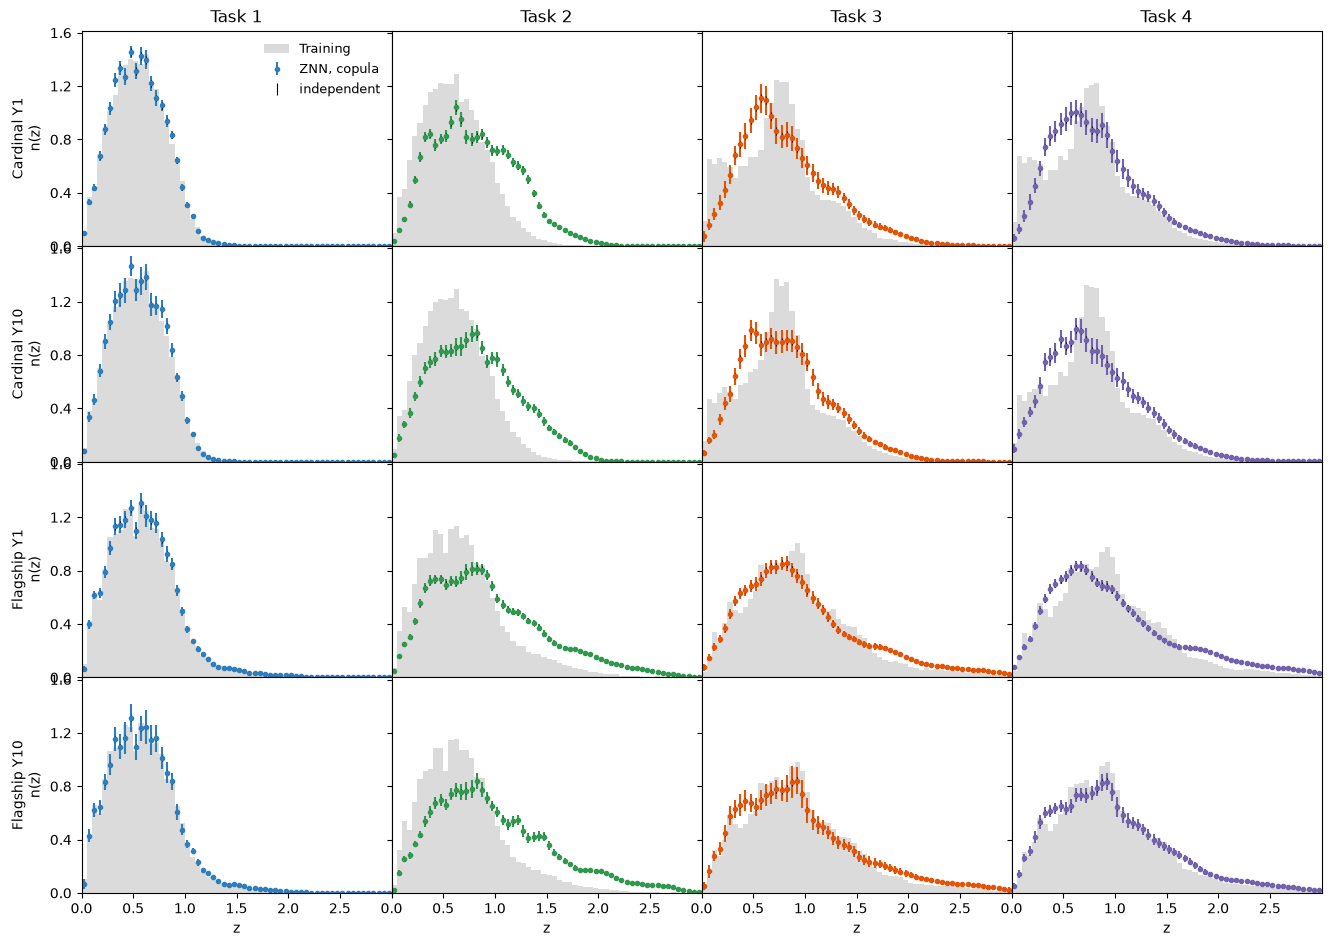

In [14]:
if PREDICT_TEST:
    # 1. the stacked n(z) with the spread of the realizations as error bars: copula (coloured) and independent (black)
    fig, axes = plt.subplots(len(ROWS), len(TASKSETS), figsize=(16, 2.8 * len(ROWS)), sharex=True, sharey=True,
                             gridspec_kw=dict(hspace=0, wspace=0))
    for col, taskset in enumerate(TASKSETS):
        for row, (sim, scenario) in enumerate(ROWS):
            c = (taskset, sim, scenario)
            g, ax = copula_nz[c], axes[row, col]
            nz = stacked_nz[c]
            ax.hist(train_z[c], bins=NZ_BINS, density=True, histtype="stepfilled", color=TRAIN_COLOR, alpha=0.35,
                    label="Training")
            ax.errorbar(z_mid, nz, yerr=g["nz_copula"].std(0, ddof=1), ls="none", marker="o", ms=3,
                        color=COLORS[taskset], elinewidth=1.5, capsize=0, label="ZNN, copula")
            ax.errorbar(z_mid, nz, yerr=g["nz_indep"].std(0, ddof=1), fmt="none", ecolor="k", elinewidth=0.8,
                        capsize=0, label="independent")
            if row == 0:
                ax.set_title(f"Task {taskset}", fontsize=12)
            if row == len(ROWS) - 1:
                ax.set_xlabel("z")
            if col == 0:
                ax.set_ylabel(f"{label(sim, scenario)}\nn(z)")
            if row == 0 and col == 0:
                ax.legend(fontsize=9, frameon=False)
    axes[0, 0].set_xlim(0, 3)
    axes[0, 0].set_ylim(bottom=0)
    axes[0, 0].set_xticks(np.arange(0, 3, 0.5))
    axes[0, 0].yaxis.set_major_locator(MaxNLocator(nbins=5, prune="upper"))
    save(fig, "nz_copula")
    plt.show()

### Submission tarball

Runs only with `SUBMISSION = True`, when preparing a submission.

Each subtask 1 file written above is validated with the challenge's own `check_pz_submission_file`. It checks that the file is valid qp, that its ancil holds `zmode` and `object_id`, and that the `object_id`s match the test file exactly; a file that passes gets flags 1 to 7. If every file passes, the 16 estimates and 16 models are packed, at the top level, into `<SUBMISSION_NAME>.tgz` in the repo root, to upload to a GitHub release of the znn code at the commit the models were trained with.

In [15]:
import tarfile

from pz_data_challenge.submit_utils import check_pz_submission_file

ALL_CHECKS = [1, 2, 3, 4, 5, 6, 7]  # what check_pz_submission_file returns for a file that passes everything

if PREDICT_TEST and SUBMISSION:
    submission_files, failed = [], []
    for c in CONFIGS:
        estimate_file = path("pz_estimate", *c)
        flags = check_pz_submission_file(estimate_file, path("test", *c))
        ok = flags == ALL_CHECKS
        print("task set {} {} {}: checks {} {}".format(*c, flags, "ok" if ok else "FAILED"))
        if not ok:
            failed.append(estimate_file)
        submission_files += [estimate_file, path("pz_model", *c)]

    assert not failed, f"estimate files failing the challenge checks, no tarball written: {failed}"
    tar_path = f"{SUBMISSION_NAME}.tgz"
    with tarfile.open(tar_path, "w:gz") as tar:
        for f in submission_files:
            tar.add(f, arcname=os.path.basename(f))  # flat: the challenge extracts it into submissions/<name>/
    print(f"\nwrote {tar_path}: {len(submission_files)} files, {os.path.getsize(tar_path) / 1e6:.0f} MB, from {OUT_DIR}")


task set 1 cardinal 1yr: checks [1, 2, 3, 4, 5, 6, 7] ok
task set 1 cardinal 10yr: checks [1, 2, 3, 4, 5, 6, 7] ok
task set 1 flagship 1yr: checks [1, 2, 3, 4, 5, 6, 7] ok
task set 1 flagship 10yr: checks [1, 2, 3, 4, 5, 6, 7] ok
task set 2 cardinal 1yr: checks [1, 2, 3, 4, 5, 6, 7] ok
task set 2 cardinal 10yr: checks [1, 2, 3, 4, 5, 6, 7] ok
task set 2 flagship 1yr: checks [1, 2, 3, 4, 5, 6, 7] ok
task set 2 flagship 10yr: checks [1, 2, 3, 4, 5, 6, 7] ok
task set 3 cardinal 1yr: checks [1, 2, 3, 4, 5, 6, 7] ok
task set 3 cardinal 10yr: checks [1, 2, 3, 4, 5, 6, 7] ok
task set 3 flagship 1yr: checks [1, 2, 3, 4, 5, 6, 7] ok
task set 3 flagship 10yr: checks [1, 2, 3, 4, 5, 6, 7] ok
task set 4 cardinal 1yr: checks [1, 2, 3, 4, 5, 6, 7] ok
task set 4 cardinal 10yr: checks [1, 2, 3, 4, 5, 6, 7] ok
task set 4 flagship 1yr: checks [1, 2, 3, 4, 5, 6, 7] ok
task set 4 flagship 10yr: checks [1, 2, 3, 4, 5, 6, 7] ok

wrote znn_moments.tgz: 32 files, 113 MB, from outputs/znn_pretrained_popcosmos_

# Part C: challenge points

Runs only with `SUBMISSION = True`, when preparing a submission.

Part A's held-out metrics graded against the challenge tiers (`pz_data_challenge.scoring.metric_dict`). There is one point per nested range a metric falls inside, so at most 3 per metric and 21 per configuration.

A 0 under `outlier` is usually not a real failure. qp computes that metric from a spline fit to the PIT quantiles, which breaks down (negative or huge values) when PIT piles up at 0 or 1, so check the PIT histograms in Part A. The challenge evaluator makes the same call, so these are the points it would award.


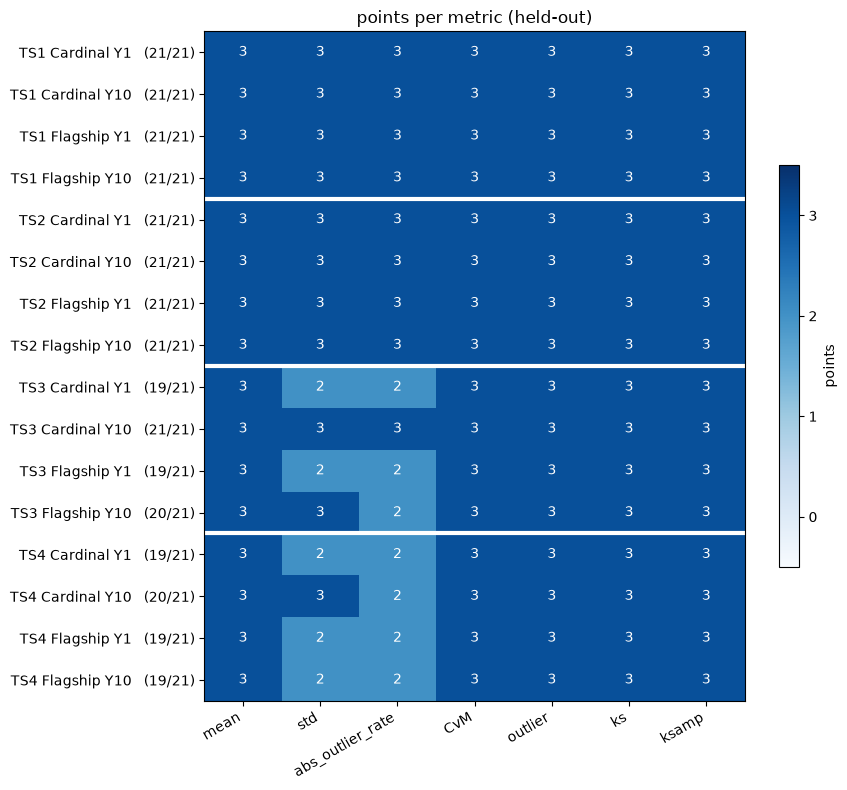

total points per task set (sum over its 4 configurations, held-out):
taskset
1    84
2    84
3    79
4    77 
(out of 84 each)


In [16]:
def tier_points(values):
    return {name: sum(lo <= float(values[name]) <= hi for lo, hi in ranges) for name, ranges in scoring.metric_dict.items()}


if SUBMISSION:
    points = pd.DataFrame({k: tier_points(v) for k, v in results.items()}).T
    points.index.names = table.index.names
    points["total"] = points.sum(axis=1)
    N_MAX = sum(len(r) for r in scoring.metric_dict.values())

    labels = [f"TS{t} {label(s, y)}" for t, s, y in points.index]
    metrics = list(scoring.metric_dict)

    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(points[metrics].to_numpy(), cmap="Blues", vmin=-0.5, vmax=3.5, aspect="auto")
    for (i, j), v in np.ndenumerate(points[metrics].to_numpy()):
        ax.text(j, i, int(v), ha="center", va="center", fontsize=10, color="white" if v >= 2 else "black")
    ax.set_xticks(range(len(metrics)), metrics, rotation=30, ha="right")
    ax.set_yticks(range(len(labels)), [f"{l}   ({t}/{N_MAX})" for l, t in zip(labels, points["total"])])
    for y in (3.5, 7.5, 11.5):
        ax.axhline(y, color="white", lw=3)
    ax.set_title("points per metric (held-out)")
    fig.colorbar(im, ax=ax, ticks=[0, 1, 2, 3], shrink=0.6, label="points")
    fig.tight_layout()
    save(fig, "points")
    plt.show()

    print("total points per task set (sum over its 4 configurations, held-out):")
    print(points["total"].groupby(level="taskset").sum().to_string(), f"\n(out of {4 * N_MAX} each)")


# Appendix: what the CNN sees

The model does not take the band magnitudes as a list. Each magnitude (minus the reference i band) is spread over wavelength with its filter curve, and the result is averaged into `n_bins` equal-width wavelength bins. This gives a continuous curve (channel 0 of `X`), which is shown here for a few held-out galaxies across redshift.

- **Left:** the encoding of the catalogue photometry, drawn through the `n_bins` bin centres. The filter curves are in the strip on top. Bins with no observed band are 0 (and have 0 in the coverage channel).
- **Right:** the predicted p(z) for that galaxy from Part A, with the reference redshift as a dashed line.

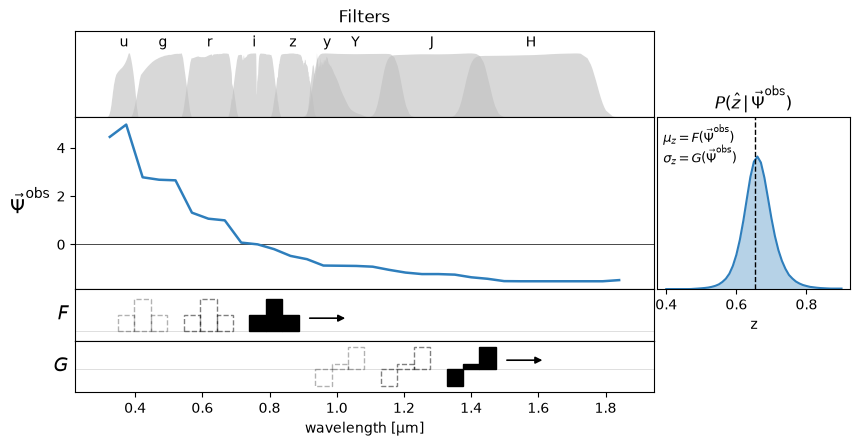

In [32]:
EXAMPLE = (1, "cardinal", "1yr")  # (task set, sim, depth)
Z_TARGETS = [0.7] #, 1.1, 1.6]# 2.2]  # one galaxy picked near each reference redshift
IMAG_RANGE = (22.0, 23.5)  # i-band range of the galaxies shown
ZGRID = np.linspace(0.4, 0.9, 51)
rng = np.random.default_rng(1)

train = znn.read_catalog(path("training", *EXAMPLE))
_, idx_val = train_test_split(np.arange(len(train)), test_size=VAL_FRAC, random_state=SEED)
h = heldout[EXAMPLE]
_, features = znn.load_model_file(path("pz_model", *EXAMPLE))
bands, curves, cfg = features["bands"], features["filter_curves"], features["config"]

in_mag = (h["mag_i"] > IMAG_RANGE[0]) & (h["mag_i"] < IMAG_RANGE[1])
picks = [rng.choice(np.flatnonzero(in_mag & (np.abs(h["z_ref"] - zt) < 0.05))) for zt in Z_TARGETS]
gal = train.iloc[idx_val[picks]]

# wavelength bin centres, as catalog_to_XY builds them
lambda_common = np.linspace(min(c[:, 0].min() for c in curves.values()), max(c[:, 0].max() for c in curves.values()), cfg["n_lambda"])
lam_bins, _ = znn.make_lambda_bins(lambda_common, cfg["n_bins"])
lam_eff = {b: np.sum(c[:, 0] * c[:, 1]) / np.sum(c[:, 1]) for b, c in curves.items()}

X_obs, _ = znn.catalog_to_XY(gal, **features)

ENC = COLORS[EXAMPLE[0]]
F_COLOR, G_COLOR = "k", "k"  # the two toy convolution filters
um = 1e-4  # filter curves are in Angstrom
fig, axes = plt.subplots(
    len(picks) + 3, 2, figsize=(10, 2.3 * len(picks) + 2.4), sharex="col",
    gridspec_kw=dict(height_ratios=[0.5] + [1] * len(picks) + [0.3, 0.3], width_ratios=[3, 1], hspace=0.0, wspace=0.01),
)
for b, c in curves.items():
    axes[0, 0].fill_between(c[:, 0] * um, c[:, 1] / c[:, 1].max(), color="0.75", alpha=0.6, lw=0)
    axes[0, 0].text(lam_eff[b] * um, 1.05, b, ha="center", va="bottom", fontsize=10)
axes[0, 0].set_ylim(0, 1.35)
axes[0, 0].set_yticks([])
axes[0, 1].axis("off")

# toy 1D convolution filters F and G sliding over the SED's wavelength bins, one panel each (the bottom rows): a few
# discrete taps, one box per bin, with outlines at earlier positions and an arrow for the direction of the sweep
lam = lam_bins * um
dl = lam[1] - lam[0]
for ax, name, color, taps, starts in [
    (axes[-2, 0], "F", F_COLOR, np.array([0.5, 1.0, 0.5]), (1, 5, 9)),
    (axes[-1, 0], "G", G_COLOR, np.array([-0.8, 0.2, 1.0]), (13, 17, 21)),
]:
    for k, i0 in enumerate(starts):
        last = k == len(starts) - 1
        ax.bar(lam[i0:i0 + len(taps)], taps, width=dl, color=color if last else "none",
               ec=color, lw=1.0, ls="-" if last else "--", alpha=1 if last else 0.3 + 0.2 * k)
    ax.axhline(0, color="0.85", lw=0.6, zorder=0)
    end = lam[starts[-1] + len(taps) - 1] + dl
    ax.annotate("", xy=(end + 2.5 * dl, 0.4), xytext=(end, 0.4),
                arrowprops=dict(arrowstyle="-|>", color=color, lw=1.2))
    ax.set_ylim(min(taps.min(), 0) - 0.3, taps.max() + 0.3)
    ax.set_yticks([])
    ax.set_ylabel(f"${name}$", color=color, fontsize=14, rotation=0, ha="right", va="center")
axes[-2, 1].axis("off")
axes[-1, 1].axis("off")

for row, (k, j) in enumerate(zip(range(len(picks)), picks), start=1):
    ax = axes[row, 0]
    ax.axhline(0, color="k", lw=0.5)
    ax.plot(lam_bins * um, X_obs[k, :, 0], color=ENC, lw=1.8)
    ax.set_ylabel(r"$\vec{\Psi}^{\rm obs}$", fontsize=14, rotation=0, ha="right", va="center")

    ax = axes[row, 1]
    pdf = np.squeeze(h["pz"][[j]].pdf(ZGRID))
    ax.fill_between(ZGRID, pdf, color=ENC, alpha=0.35, lw=0)
    ax.plot(ZGRID, pdf, color=ENC, lw=1.5)
    ax.axvline(h["z_ref"][j], color="k", ls="--", lw=1)
    ax.set_yticks([])
    ax.set_ylim(0, 1.3 * pdf.max())
    # F sets the mean and G the width of the p(z): a legend in the top panel only, on the side away from the peak
    if row == 1:
        right = h["mean"][j] < ZGRID.mean()
        ax.text(0.97 if right else 0.03, 0.95,
                "$\\mu_z = F(\\vec{\\Psi}^{\\rm obs})$\n$\\sigma_z = G(\\vec{\\Psi}^{\\rm obs})$",
                transform=ax.transAxes, ha="right" if right else "left", va="top", fontsize=9, linespacing=1.6)

axes[-1, 0].set_xlabel("wavelength [μm]")
# the p(z) column ends at the last SED row, above the empty slots next to the conv. filters
axes[-3, 1].tick_params(labelbottom=True)
axes[-3, 1].set_xlabel("z")
axes[0, 0].set_title("Filters", fontsize=12)
axes[1, 1].set_title(r"$P(\hat{z}\,|\,\vec{\Psi}^{\rm obs})$", fontsize=12)
save(fig, "encoding")
plt.show()